In [1]:
%pip install pandas numpy matplotlib seaborn scipy openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import chi2_contingency
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid")

In [3]:
if Path("cleaned_sales_dataset.csv").exists():
    df = pd.read_csv("cleaned_sales_dataset.csv")
elif Path("ApexPlanet_DataAnalytics_Dataset.xlsx").exists():
    df = pd.read_excel("ApexPlanet_DataAnalytics_Dataset.xlsx")
else:
    raise FileNotFoundError(
        "Place cleaned_sales_dataset.csv or "
        "ApexPlanet_DataAnalytics_Dataset.xlsx "
        "in the same folder as this notebook."
    )

df["Order_Date"] = pd.to_datetime(
    df["Order_Date"], errors="coerce"
)

for col in ["Age", "Quantity", "Unit_Price", "Total_Sales"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1000, 12)


,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales
0,ORD100002,2025-02-25,CUST5529,Customer_227,30.00,Female,Bengaluru,Rice,Grocery,7,"2,829.77","19,808.39"
1,ORD100003,2025-10-14,CUST3127,Customer_182,63.00,Male,Bengaluru,Book,Education,5,"27,906.16","139,530.80"
2,ORD100004,2025-05-13,CUST8887,Customer_487,62.00,Female,Bengaluru,Book,Education,8,"37,491.06","299,928.48"
3,ORD100005,2025-12-02,CUST2515,Customer_470,65.00,Female,Kolkata,Mobile,Electronics,9,"28,541.36","256,872.24"
4,ORD100006,2025-11-20,CUST4796,Customer_380,44.00,Male,Bengaluru,Rice,Grocery,10,"14,036.59","140,365.90"


In [4]:
quality_report = pd.DataFrame({
    "Metric": [
        "Total Rows",
        "Total Columns",
        "Duplicate Rows",
        "Missing Order Dates",
        "Missing Ages",
        "Missing Cities",
        "Missing Quantities",
        "Missing Unit Prices",
        "Missing Total Sales"
    ],
    "Value": [
        len(df),
        len(df.columns),
        df.duplicated().sum(),
        df["Order_Date"].isna().sum(),
        df["Age"].isna().sum(),
        df["City"].isna().sum(),
        df["Quantity"].isna().sum(),
        df["Unit_Price"].isna().sum(),
        df["Total_Sales"].isna().sum()
    ]
})

display(quality_report)

,Metric,Value
0,Total Rows,1000
1,Total Columns,12
2,Duplicate Rows,0
3,Missing Order Dates,0
4,Missing Ages,20
5,Missing Cities,13
6,Missing Quantities,0
7,Missing Unit Prices,0
8,Missing Total Sales,0


In [5]:
df["Calculated_Sales"] = df["Quantity"] * df["Unit_Price"]

df["Sales_Difference"] = (
    df["Total_Sales"] - df["Calculated_Sales"]
).abs()

print(
    "Rows with sales calculation mismatch:",
    (df["Sales_Difference"] > 0.01).sum()
)

Rows with sales calculation mismatch: 0


In [6]:
total_sales = df["Total_Sales"].sum()
total_orders = df["Order_ID"].nunique()
unique_customers = df["Customer_ID"].nunique()
total_quantity = df["Quantity"].sum()

order_sales = df.groupby("Order_ID")["Total_Sales"].sum()
average_order_value = order_sales.mean()

kpi_table = pd.DataFrame({
    "KPI": [
        "Total Sales",
        "Total Orders",
        "Unique Customers",
        "Total Quantity Sold",
        "Average Order Value"
    ],
    "Value": [
        total_sales,
        total_orders,
        unique_customers,
        total_quantity,
        average_order_value
    ],
    "Business Importance": [
        "Measures overall revenue",
        "Measures order volume",
        "Measures customer reach",
        "Measures total units sold",
        "Measures average revenue per order"
    ]
})

display(kpi_table)

,KPI,Value,Business Importance
0,Total Sales,"139,399,439.65",Measures overall revenue
1,Total Orders,992.00,Measures order volume
2,Unique Customers,947.00,Measures customer reach
3,Total Quantity Sold,"5,435.00",Measures total units sold
4,Average Order Value,"140,523.63",Measures average revenue per order


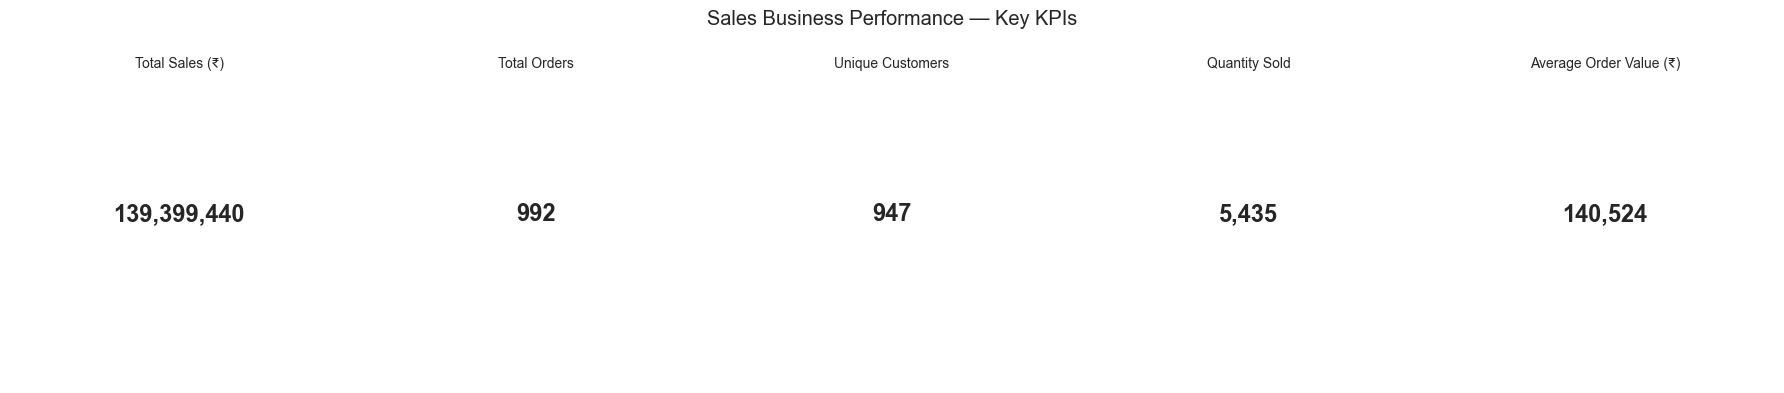

In [7]:
kpi_labels = [
    "Total Sales (₹)",
    "Total Orders",
    "Unique Customers",
    "Quantity Sold",
    "Average Order Value (₹)"
]

kpi_values = [
    total_sales,
    total_orders,
    unique_customers,
    total_quantity,
    average_order_value
]

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for ax, label, value in zip(axes, kpi_labels, kpi_values):
    ax.text(
        0.5, 0.55, f"{value:,.0f}",
        ha="center", va="center",
        fontsize=17, fontweight="bold"
    )
    ax.set_title(label, fontsize=10)
    ax.axis("off")

plt.suptitle("Sales Business Performance — Key KPIs")
plt.tight_layout()
plt.show()

,Total_Sales
Product,
Laptop,"25,443,008.51"
Mobile,"25,335,573.19"
Book,"25,031,689.40"
Rice,"22,231,711.28"
Chair,"21,521,561.48"
Shoes,"19,835,895.79"


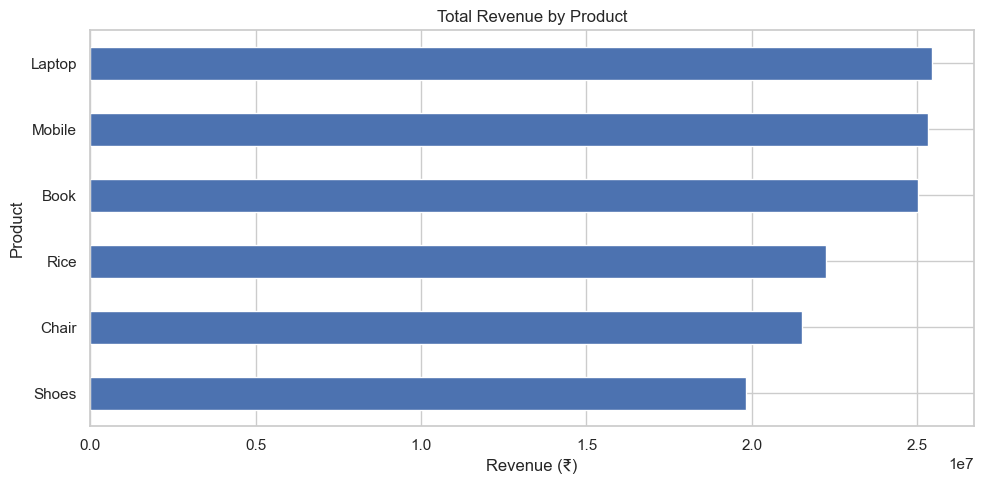

In [8]:
product_sales = (
    df.groupby("Product")["Total_Sales"]
    .sum()
    .sort_values(ascending=False)
)

display(product_sales.to_frame("Total_Sales"))

plt.figure(figsize=(10, 5))
product_sales.sort_values().plot(kind="barh")

plt.title("Total Revenue by Product")
plt.xlabel("Revenue (₹)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

,Total_Sales
Category,
Electronics,"50,778,581.70"
Education,"25,031,689.40"
Grocery,"22,231,711.28"
Furniture,"21,521,561.48"
Fashion,"19,835,895.79"


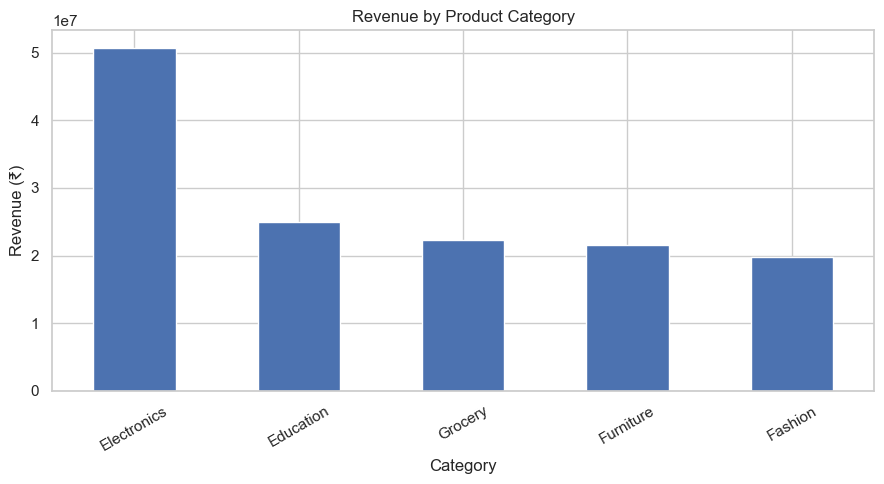

In [9]:
category_sales = (
    df.groupby("Category")["Total_Sales"]
    .sum()
    .sort_values(ascending=False)
)

display(category_sales.to_frame("Total_Sales"))

plt.figure(figsize=(9, 5))
category_sales.plot(kind="bar")

plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

,Total_Sales
City,
Patna,"19,285,966.89"
Kolkata,"18,884,349.57"
Bengaluru,"18,773,574.32"
Mumbai,"18,757,050.17"
Hyderabad,"17,166,766.87"
Delhi,"16,097,079.00"
Pune,"14,513,175.90"
Gaya,"14,380,859.39"


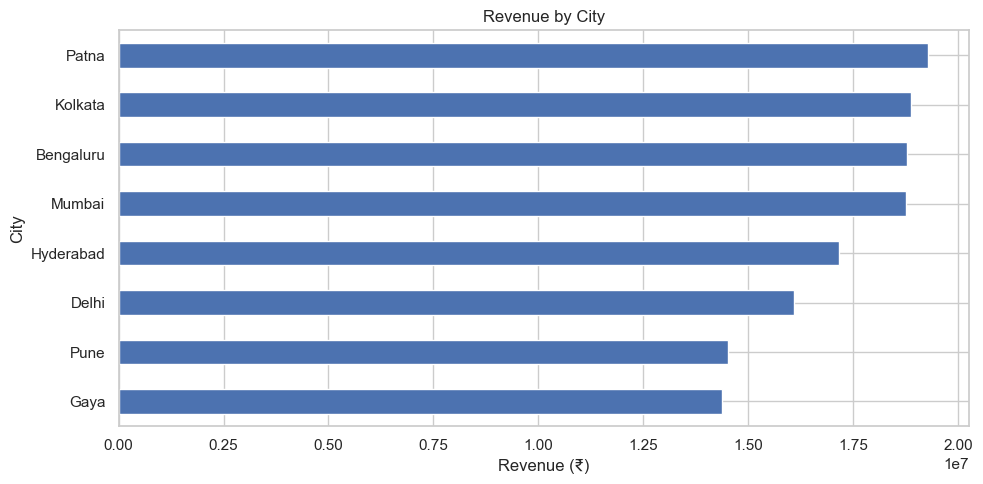

In [10]:
city_sales = (
    df.groupby("City")["Total_Sales"]
    .sum()
    .sort_values(ascending=False)
)

display(city_sales.to_frame("Total_Sales"))

plt.figure(figsize=(10, 5))
city_sales.sort_values().plot(kind="barh")

plt.title("Revenue by City")
plt.xlabel("Revenue (₹)")
plt.ylabel("City")
plt.tight_layout()
plt.show()

,Total_Sales
Year_Month,
2025-01,"10,096,190.73"
2025-02,"11,511,181.46"
2025-03,"13,059,899.94"
2025-04,"12,222,700.17"
2025-05,"10,984,689.25"
2025-06,"12,912,332.64"
2025-07,"11,746,226.80"
2025-08,"9,448,471.22"
2025-09,"9,179,896.29"


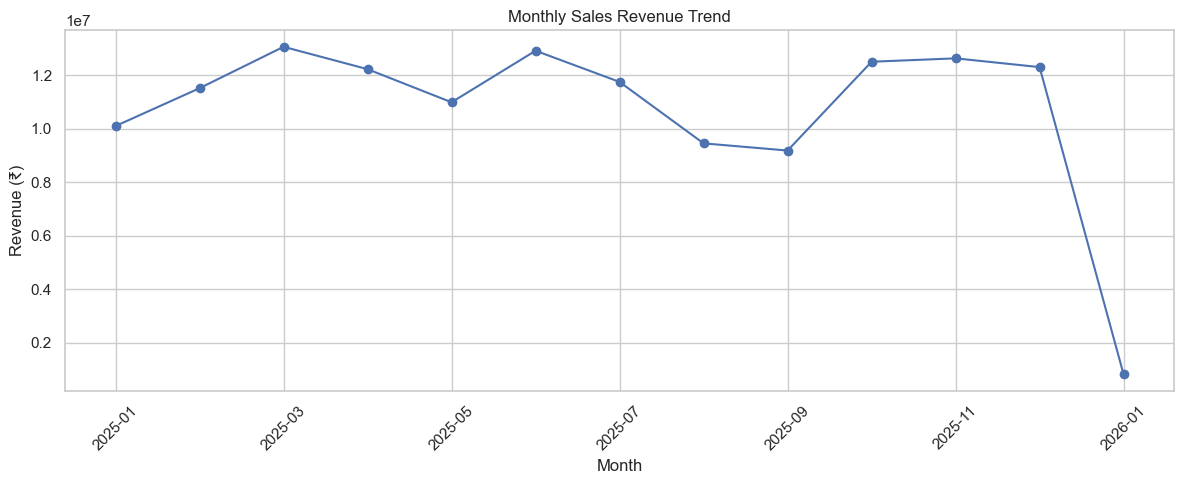

In [11]:
monthly_sales = (
    df.dropna(subset=["Order_Date"])
    .assign(
        Year_Month=lambda x:
        x["Order_Date"].dt.to_period("M").astype(str)
    )
    .groupby("Year_Month")["Total_Sales"]
    .sum()
    .sort_index()
)

display(monthly_sales.to_frame("Total_Sales"))

plt.figure(figsize=(12, 5))
monthly_sales.plot(marker="o")

plt.title("Monthly Sales Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
gender_orders = (
    df[df["Gender"].isin(["Male", "Female"])]
    .groupby(["Order_ID", "Gender"], as_index=False)
    .agg(Order_Sales=("Total_Sales", "sum"))
)

male_sales = gender_orders.loc[
    gender_orders["Gender"] == "Male", "Order_Sales"
].dropna()

female_sales = gender_orders.loc[
    gender_orders["Gender"] == "Female", "Order_Sales"
].dropna()

print("Male orders:", len(male_sales))
print("Female orders:", len(female_sales))

print(f"Male mean order sales: ₹{male_sales.mean():,.2f}")
print(f"Female mean order sales: ₹{female_sales.mean():,.2f}")

t_statistic, p_value = stats.ttest_ind(
    male_sales,
    female_sales,
    equal_var=False
)

print("\nWelch's t-test")
print("T-statistic:", round(t_statistic, 4))
print("P-value:", round(p_value, 6))

alpha = 0.05

if p_value < alpha:
    print("Decision: Reject the null hypothesis.")
    print(
        "Conclusion: A statistically significant difference "
        "in mean order sales was detected between the groups."
    )
else:
    print("Decision: Fail to reject the null hypothesis.")
    print(
        "Conclusion: There is insufficient evidence of a "
        "difference in mean order sales between the groups."
    )

Male orders: 505
Female orders: 488
Male mean order sales: ₹143,492.18
Female mean order sales: ₹137,163.71

Welch's t-test
T-statistic: 0.8438
P-value: 0.398977
Decision: Fail to reject the null hypothesis.
Conclusion: There is insufficient evidence of a difference in mean order sales between the groups.


In [13]:
n_male = len(male_sales)
n_female = len(female_sales)

var_male = male_sales.var(ddof=1)
var_female = female_sales.var(ddof=1)

mean_difference = male_sales.mean() - female_sales.mean()

standard_error = np.sqrt(
    var_male / n_male + var_female / n_female
)

degrees_freedom = (
    (var_male / n_male + var_female / n_female) ** 2
    /
    (
        (var_male / n_male) ** 2 / (n_male - 1)
        +
        (var_female / n_female) ** 2 / (n_female - 1)
    )
)

critical_value = stats.t.ppf(
    0.975, degrees_freedom
)

ci_lower = mean_difference - critical_value * standard_error
ci_upper = mean_difference + critical_value * standard_error

print(f"Mean difference: ₹{mean_difference:,.2f}")
print(f"95% confidence interval: ₹{ci_lower:,.2f} to ₹{ci_upper:,.2f}")

Mean difference: ₹6,328.47
95% confidence interval: ₹-8,388.97 to ₹21,045.91


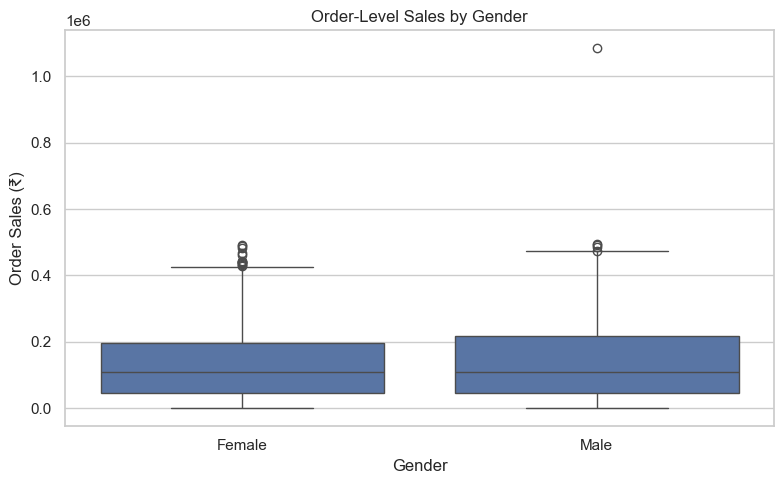

In [14]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=gender_orders,
    x="Gender",
    y="Order_Sales"
)

plt.title("Order-Level Sales by Gender")
plt.xlabel("Gender")
plt.ylabel("Order Sales (₹)")
plt.tight_layout()
plt.show()

In [15]:
test_data = df[
    df["Gender"].isin(["Male", "Female"])
    & df["Category"].notna()
    & (df["Category"] != "Unknown")
]

contingency_table = pd.crosstab(
    test_data["Gender"],
    test_data["Category"]
)

display(contingency_table)

chi2_stat, chi_p_value, degrees_freedom, expected = (
    chi2_contingency(contingency_table)
)

print("Chi-square statistic:", round(chi2_stat, 4))
print("Degrees of freedom:", degrees_freedom)
print("P-value:", round(chi_p_value, 6))

if chi_p_value < 0.05:
    print("Decision: Reject the null hypothesis.")
    print(
        "Conclusion: There is statistical evidence of an "
        "association between recorded gender and product category."
    )
else:
    print("Decision: Fail to reject the null hypothesis.")
    print(
        "Conclusion: There is insufficient statistical evidence "
        "of an association between recorded gender and product category."
    )

expected_table = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

print(
    "All expected cell counts are at least 5:",
    bool((expected_table >= 5).all().all())
)

Category,Education,Electronics,Fashion,Furniture,Grocery
Gender,,,,,
Female,96,158,89,74,72
Male,82,196,67,85,81


Chi-square statistic: 9.0936
Degrees of freedom: 4
P-value: 0.058802
Decision: Fail to reject the null hypothesis.
Conclusion: There is insufficient statistical evidence of an association between recorded gender and product category.
All expected cell counts are at least 5: True


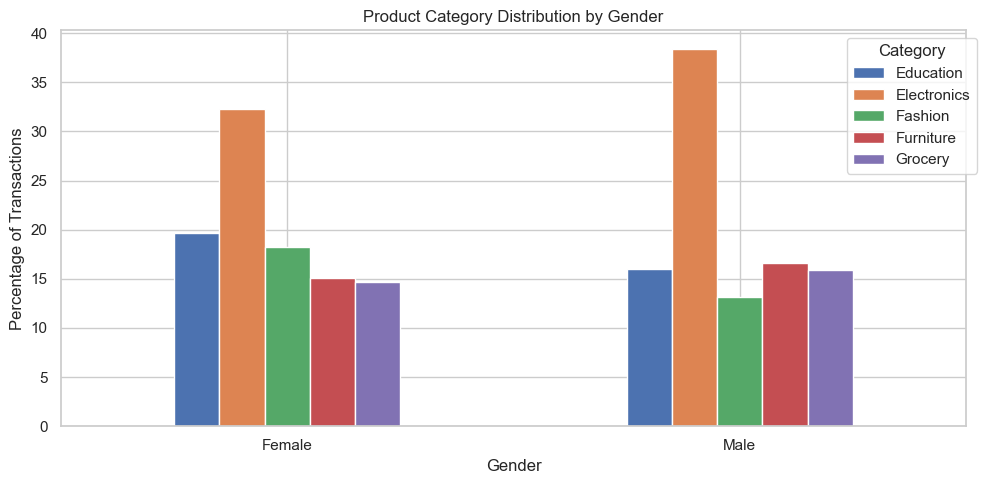

In [16]:
category_distribution = pd.crosstab(
    test_data["Gender"],
    test_data["Category"],
    normalize="index"
) * 100

category_distribution.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Product Category Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Percentage of Transactions")
plt.xticks(rotation=0)
plt.legend(title="Category", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

In [17]:
top_product = product_sales.idxmax()
top_category = category_sales.idxmax()
top_city = city_sales.idxmax()
best_month = monthly_sales.idxmax()

print("=" * 60)
print("TASK 4: DATA STORYTELLING — BUSINESS SUMMARY")
print("=" * 60)

print(f"\n1. Total Revenue: ₹{total_sales:,.2f}")
print(f"2. Total Orders: {total_orders:,}")
print(f"3. Unique Customers: {unique_customers:,}")
print(f"4. Average Order Value: ₹{average_order_value:,.2f}")

print(
    f"\n5. Top Product: {top_product} "
    f"(₹{product_sales[top_product]:,.2f})"
)

print(
    f"6. Top Category: {top_category} "
    f"(₹{category_sales[top_category]:,.2f})"
)

print(
    f"7. Top City: {top_city} "
    f"(₹{city_sales[top_city]:,.2f})"
)

print(
    f"8. Highest-Revenue Month: {best_month} "
    f"(₹{monthly_sales[best_month]:,.2f})"
)

print(f"\n9. Gender t-test p-value: {p_value:.6f}")
print(f"10. Gender-category chi-square p-value: {chi_p_value:.6f}")

print("\nBUSINESS INTERPRETATION")
print("-" * 60)
print(f"- Review the sales drivers behind {top_product}.")
print(f"- Investigate what contributes to revenue in {top_category}.")
print(f"- Compare customer demand and order value in {top_city}.")
print("- Investigate monthly peaks before making inventory decisions.")
print("- Use statistical test results to assess the observed patterns.")
print("- Statistical association does not establish causation.")

TASK 4: DATA STORYTELLING — BUSINESS SUMMARY

1. Total Revenue: ₹139,399,439.65
2. Total Orders: 992
3. Unique Customers: 947
4. Average Order Value: ₹140,523.63

5. Top Product: Laptop (₹25,443,008.51)
6. Top Category: Electronics (₹50,778,581.70)
7. Top City: Patna (₹19,285,966.89)
8. Highest-Revenue Month: 2025-03 (₹13,059,899.94)

9. Gender t-test p-value: 0.398977
10. Gender-category chi-square p-value: 0.058802

BUSINESS INTERPRETATION
------------------------------------------------------------
- Review the sales drivers behind Laptop.
- Investigate what contributes to revenue in Electronics.
- Compare customer demand and order value in Patna.
- Investigate monthly peaks before making inventory decisions.
- Use statistical test results to assess the observed patterns.
- Statistical association does not establish causation.


In [18]:
output_folder = Path("Task_4_Output")
output_folder.mkdir(exist_ok=True)

with pd.ExcelWriter(
    output_folder / "Task_4_Analysis_Results.xlsx",
    engine="openpyxl"
) as writer:

    quality_report.to_excel(
        writer, sheet_name="Data_Quality", index=False
    )

    kpi_table.to_excel(
        writer, sheet_name="KPIs", index=False
    )

    product_sales.to_frame("Revenue").to_excel(
        writer, sheet_name="Product_Sales"
    )

    category_sales.to_frame("Revenue").to_excel(
        writer, sheet_name="Category_Sales"
    )

    city_sales.to_frame("Revenue").to_excel(
        writer, sheet_name="City_Sales"
    )

    monthly_sales.to_frame("Revenue").to_excel(
        writer, sheet_name="Monthly_Sales"
    )

    contingency_table.to_excel(
        writer, sheet_name="Chi_Square_Counts"
    )

    category_distribution.to_excel(
        writer, sheet_name="Category_Distribution"
    )

    pd.DataFrame({
        "Metric": [
            "T-statistic",
            "T-test p-value",
            "Mean difference",
            "95% CI lower",
            "95% CI upper",
            "Chi-square statistic",
            "Chi-square p-value"
        ],
        "Value": [
            t_statistic,
            p_value,
            mean_difference,
            ci_lower,
            ci_upper,
            chi2_stat,
            chi_p_value
        ]
    }).to_excel(
        writer, sheet_name="Statistical_Tests", index=False
    )

print("Excel results saved to:")
print((output_folder / "Task_4_Analysis_Results.xlsx").resolve())

Excel results saved to:
C:\Users\hp\Desktop\Internship\Task 4\Task_4_Output\Task_4_Analysis_Results.xlsx


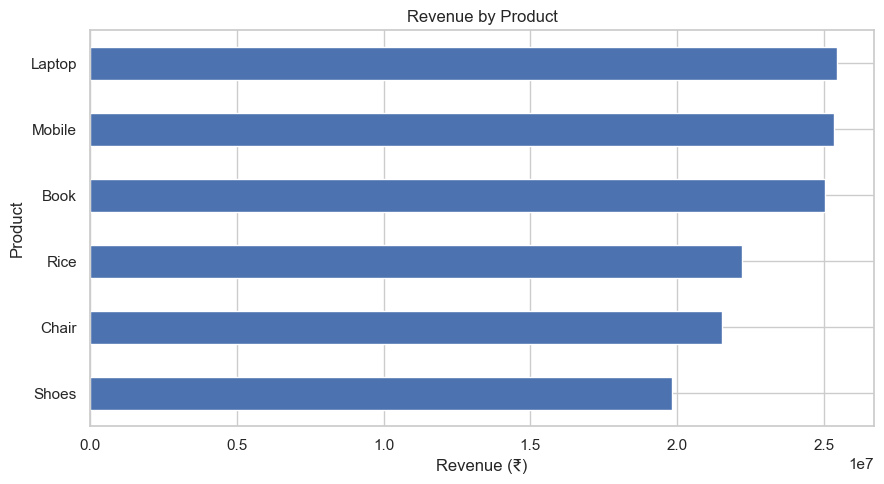

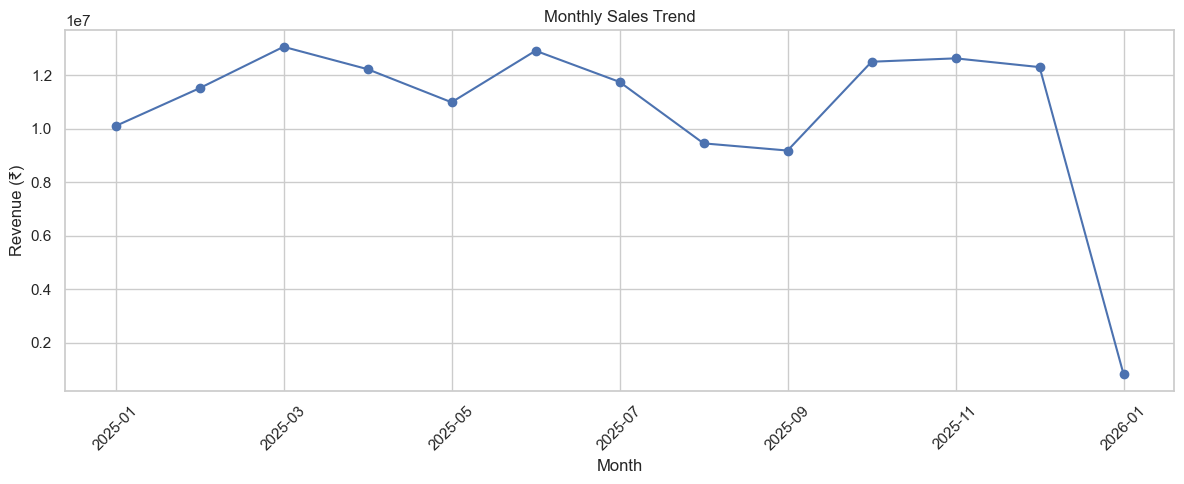

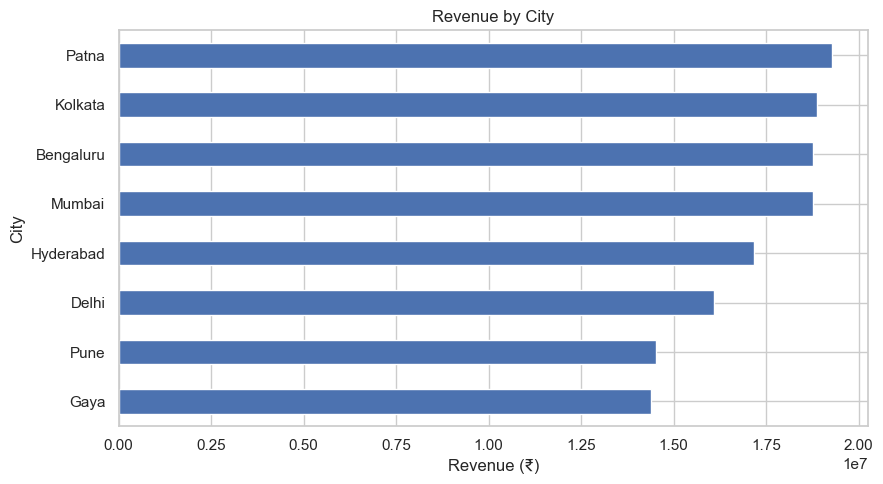

Charts saved in: C:\Users\hp\Desktop\Internship\Task 4\Task_4_Output


In [19]:
# Revenue by product
plt.figure(figsize=(9, 5))
product_sales.sort_values().plot(kind="barh")
plt.title("Revenue by Product")
plt.xlabel("Revenue (₹)")
plt.tight_layout()
plt.savefig(
    output_folder / "revenue_by_product.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

# Monthly sales trend
plt.figure(figsize=(12, 5))
monthly_sales.plot(marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    output_folder / "monthly_sales_trend.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

# City-wise revenue
plt.figure(figsize=(9, 5))
city_sales.sort_values().plot(kind="barh")
plt.title("Revenue by City")
plt.xlabel("Revenue (₹)")
plt.tight_layout()
plt.savefig(
    output_folder / "revenue_by_city.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

print("Charts saved in:", output_folder.resolve())